# 04 · Model 3: both views together

**Idea.** Model 1 says which alerts fired together, Model 2 which alerts say the same thing. Model 3 combines them with the other columns into one label per alert, `Final_Cluster`, that maintenance can sort by.

**How** (`src/central_logging/combine.py`)
1. Merge the Model 2 output (`alertId`, `Text_Cluster`) with the Model 1 output on `alertId`
2. Label-encode `alert_combined` and `alertPlc`
3. Features: `Text_Cluster`, `alertTotalDuration`, `alertIsBandStop`, `alertCategory`, `alertId`, `Cluster`, `alertBegin_hour`
4. StandardScaler, then PCA to 6 components
5. **MiniBatchKMeans with 10 clusters**, updated with `partial_fit` PLC by PLC, so each new file updates the model instead of retraining it. Scaler and PCA are fitted on the first file and reused after that

There are no labels for this view, so the project judged it with internal measures (silhouette, Davies-Bouldin) and by looking at what each cluster contains.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from central_logging import config, plotting
from central_logging.plotting import SERIES, MUTED, TEXT, TEXT_2

plotting.use_style()
pd.set_option("display.max_colwidth", 90)
RESULTS = ROOT / "results"
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
scores = {f"min_samples {m}": json.loads((RESULTS / f"scores_min_samples_{m}.json").read_text())["model3"]
          for m in (7, 3)}
pd.DataFrame(scores).round(3)

,min_samples 7,min_samples 3
alerts,86306.000,86306.000
final_clusters,7.000,8.000
silhouette,0.179,0.171
davies_bouldin,1.149,1.108
ari_vs_family,0.061,0.035


## What each cluster contains
Week 2, application settings (`min_samples = 7` in Model 1). `median_hour_utc` is the hour bucket from Model 1, in UTC; `median_text_cluster` is the typical `Text_Cluster` number.

In [3]:
profile = pd.read_csv(RESULTS / "model3_profile_min_samples_7.csv")

def describe(r):
    if r.band_stop_share >= 0.9:
        return "line stopped"
    if r.median_duration_s >= 600:
        return f"very long alerts (median {r.median_duration_s / 60:.0f} min)"
    if r.median_duration_s >= 60:
        return f"long alerts (median {r.median_duration_s / 60:.1f} min)"
    if r.top_family == "organization" and r.top_family_share >= 0.7:
        return "organizational messages"
    if r.top_family == "misc" and r.top_family_share >= 0.7:
        return "other messages"
    if r.alerts < 50:
        return "a handful of alerts"
    return "short technical alerts"

profile["what it holds"] = profile.apply(describe, axis=1)
profile[["Final_Cluster", "what it holds", "alerts", "share", "band_stop_share", "median_duration_s",
         "median_hour_utc", "median_text_cluster", "top_family", "top_family_share"]].round(3)

,Final_Cluster,what it holds,alerts,share,band_stop_share,median_duration_s,median_hour_utc,median_text_cluster,top_family,top_family_share
0,0,line stopped,9753,0.113,1.000,2.420,11.0,499.0,drive,0.163
1,1,short technical alerts,48910,0.567,0.000,1.419,13.0,639.0,conveyor,0.218
2,4,short technical alerts,11949,0.138,0.000,1.425,4.0,585.0,conveyor,0.223
3,5,other messages,1390,0.016,0.063,1.297,11.0,171.0,misc,1.000
4,6,long alerts (median 7.4 min),508,0.006,0.124,446.635,11.0,479.0,conveyor,0.187
5,7,short technical alerts,8750,0.101,0.000,1.373,12.0,50.0,drive,0.278
6,9,organizational messages,5046,0.058,0.000,1.350,11.0,291.5,organization,1.000


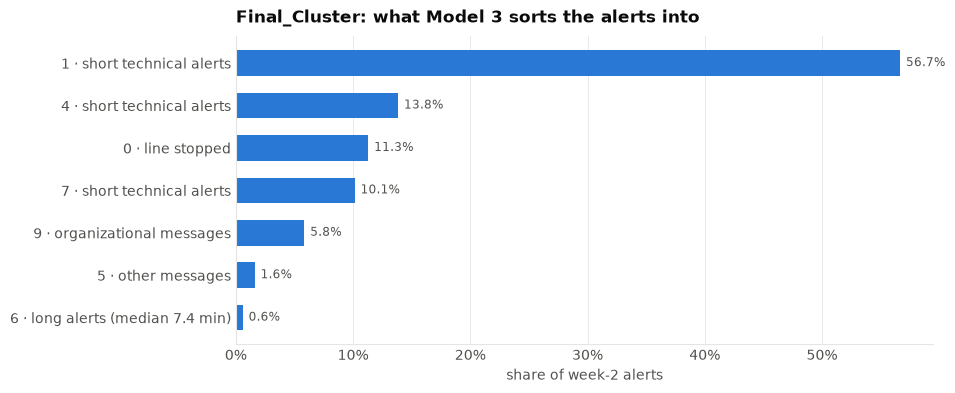

In [4]:
p = profile[profile.alerts >= 50].sort_values("alerts")       # leaves out clusters with a handful of alerts
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh([f"{c} · {d}" for c, d in zip(p.Final_Cluster, p["what it holds"])], p.share,
               color=SERIES[0], height=0.6)
for b, v in zip(bars, p.share):
    ax.text(v + 0.005, b.get_y() + b.get_height() / 2, f"{v:.1%}", va="center", fontsize=8.5, color=TEXT_2)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("share of week-2 alerts")
ax.set_title("Final_Cluster: what Model 3 sorts the alerts into")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "model3_clusters.png")
plt.show()

## Takeaway
- Model 3 sorts alerts by what matters for triage: alerts that stopped the line, long stoppages, organizational and other messages, and the bulk of short technical alerts, which it splits further by hour of day and by `Text_Cluster`.
- It does not name the fault (adjusted Rand index against the fault families is close to 0). That is Model 2's job; Model 3 gives a short list of alert kinds to filter on.
- `partial_fit` keeps the clusters up to date with every file, so the application never has to retrain on the full history.